In [ ]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestRegressor
import matplotlib.pyplot as plt
import seaborn as sns

# Set random seed for consistent results
np.random.seed(42)
n_samples = 200

# Generating realistic synthetic urban micro-climate features
ambient_temp = np.random.uniform(30, 42, n_samples)       # Base city temp (°C)
building_density = np.random.uniform(20, 95, n_samples)   # Concrete coverage %
green_cover = np.random.uniform(0, 50, n_samples)          # Tree/park canopy %
albedo = np.random.uniform(0.1, 0.6, n_samples)           # Surface reflectivity
humidity = np.random.uniform(40, 80, n_samples)           # Relative humidity %

# Simulating the target variable (Pedestrian-level Heat Index)
# Concrete increases heat, green cover cools it down
heat_index = ambient_temp + (building_density * 0.04) - (green_cover * 0.07) + ((0.5 - albedo) * 1.5)

# Create a Pandas DataFrame
df = pd.DataFrame({
    'Ambient_Temp': ambient_temp,
    'Building_Density': building_density,
    'Green_Cover': green_cover,
    'Albedo': albedo,
    'Humidity': humidity,
    'Heat_Index': heat_index
})

print("Dataset generated successfully!")
df.head()


Dataset generated successfully!


,Ambient_Temp,Building_Density,Green_Cover,Albedo,Humidity,Heat_Index
0,34.494481,68.152373,5.156193,0.184468,68.289545,37.332942
1,41.408572,26.310497,45.127645,0.239295,46.101562,39.693114
2,38.783927,32.122154,25.262619,0.188505,63.051534,38.767672
3,37.183902,87.391564,41.322873,0.144351,64.268602,38.320436
4,31.872224,65.482179,16.002480,0.160318,56.965227,33.880860


In [ ]:
from google.colab import sheets
sheet = sheets.InteractiveSheet(df=df)

https://docs.google.com/spreadsheets/d/1t_YxEGf3zPCqjZGb3CjOVL_Hivp_5Og4wmYTm-gm2mI/edit#gid=0


In [3]:
# 1. Define Features (X) and Target (y)
X = df[['Ambient_Temp', 'Building_Density', 'Green_Cover', 'Albedo', 'Humidity']]
y = df['Heat_Index']

# 2. Train the Random Forest Model
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X, y)
print("AI Model trained successfully!")

# 3. Test the model with real-world scenarios
# Format: [Ambient Temp, Building Density %, Green Cover %, Albedo, Humidity %]
dense_block = [[38.0, 90.0, 2.0, 0.15, 55.0]]    # High concrete, low trees
park_block = [[38.0, 25.0, 45.0, 0.45, 55.0]]     # Low concrete, high trees

pred_dense = model.predict(dense_block)
pred_park = model.predict(park_block)

print("\n--- UHI AI MODEL TEST RESULTS ---")
print(f"Base Weather Forecast: 38.0°C")
print(f"🔴 Dense Concrete Block Risk: {pred_dense[0]:.2f}°C (Severe Heat Trap!)")
print(f"🟢 Park-Adjacent Zone Risk:  {pred_park[0]:.2f}°C (Significant Cooling)")


AI Model trained successfully!

--- UHI AI MODEL TEST RESULTS ---
Base Weather Forecast: 38.0°C
🔴 Dense Concrete Block Risk: 40.42°C (Severe Heat Trap!)
🟢 Park-Adjacent Zone Risk:  36.38°C (Significant Cooling)


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(


/tmp/ipykernel_556/2821732788.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances, y=features, palette='coolwarm')


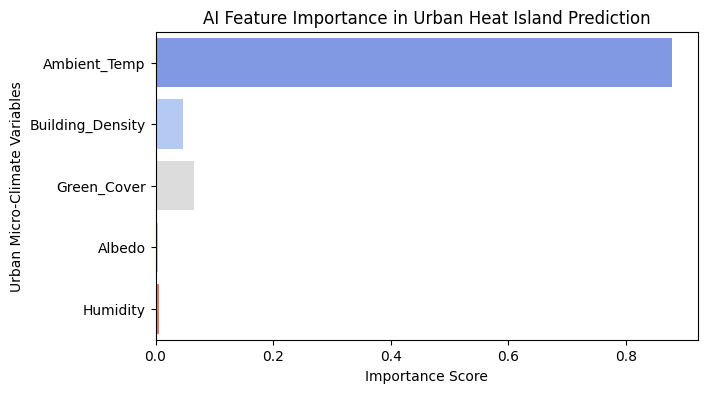

In [4]:
# Extract feature importances from the trained model
importances = model.feature_importances_
features = X.columns

plt.figure(figsize=(7, 4))
sns.barplot(x=importances, y=features, palette='coolwarm')
plt.title("AI Feature Importance in Urban Heat Island Prediction")
plt.xlabel("Importance Score")
plt.ylabel("Urban Micro-Climate Variables")
plt.show()


In [5]:
import joblib

# Save the trained model to disk
joblib.dump(model, 'uhi_model.pkl')
print("Model saved as 'uhi_model.pkl'! You can find it in the folder icon on the left sidebar of Colab.")


Model saved as 'uhi_model.pkl'! You can find it in the folder icon on the left sidebar of Colab.


In [6]:
%%writefile app.py
import streamlit as st
import joblib
import numpy as np

st.title("🌡️ Urban Heat Island (UHI) Micro-Climate Exposure Index")
st.write("Calculate hyper-local pedestrian heat risk based on urban density and green cover.")

ambient = st.slider("Base Ambient Temperature (°C)", 30.0, 45.0, 38.0)
building = st.slider("Building Density (%)", 10.0, 100.0, 80.0)
green = st.slider("Green Canopy Cover (%)", 0.0, 60.0, 10.0)
albedo = st.slider("Surface Albedo (Reflectivity)", 0.1, 0.6, 0.2)
humidity = st.slider("Relative Humidity (%)", 30.0, 90.0, 55.0)

if st.button("Calculate Micro-Climate Risk"):
    model = joblib.load('uhi_model.pkl')
    features = np.array([[ambient, building, green, albedo, humidity]])
    prediction = model.predict(features)[0]

    st.success(f"Estimated Pedestrian-Level Heat Index: **{prediction:.2f}°C**")
    if prediction > 42:
        st.error("🚨 Severe Heat Trap Risk! Avoid outdoor exposure.")
    elif prediction > 38:
        st.warning("⚠️ Moderate Heat Caution. Stay hydrated.")
    else:
        st.success("🟢 Safe Zone.")


Writing app.py
